# Análisis exploratorio del dataset — Geohelmintos en microscopía

Proyecto final de Machine Learning y de Redes Neuronales y Deep Learning (EAFIT 2026-2). Equipo:
Samuel Llano Madrigal, Laura Andrea Castrillon y Jerónimo Campuzano.

**Objetivo.** Conocer el conjunto de datos antes de entrenar: cuántos huevos hay por clase y por
partición, si las etiquetas y la partición están sanas (sin duplicados ni fuga), cómo son los
huevos (tamaño, forma, posición) y las fotos (borde del ocular, brillo, color, nitidez), y si
existe algún **atajo**: una pista de la foto, ajena al huevo, que delate la especie.

**Datos.** Chula-ParasiteEgg-11 (Universidad Chulalongkorn, reto ICIP 2022), copia completa en
Roboflow `parasites-onxa6/parasites-trgfz` v1, licencia **CC BY 4.0**. Usamos 3 de sus 11
clases: *Ascaris lumbricoides*, uncinarias (*hookworm*) y *Trichuris trichiura*. Roboflow
entregó las fotos redimensionadas a 640 × 640 por estiramiento.

**Partición.** La del equipo, generada por `src/data/filter_classes.py`: 70/15/15 por foto
original, estratificada por clase, seed 42. Las estadísticas descriptivas incluyen las tres
particiones (sirven para comprobar que se parecen); las muestras visuales y la prueba de atajos
usan solo `train` y `valid`, porque `test` está congelado hasta la evaluación final.

**Cómo correrlo.** Desde la raíz del repo, después del pipeline de datos del README (pasos 1 y 2),
con el kernel `Python (geohelmintos)`. Sin GPU; corre en el nodo de login de Apolo en pocos minutos:

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/eda_dataset.ipynb
```

In [ ]:
#Importaciones

from collections import Counter
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
# Definicion de constantes y configuracion de matplotlib y pandas
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
RAW = ROOT / "data" / "raw"       
SRC = ROOT / "data" / "roboflow"  
assert RAW.is_dir() and SRC.is_dir(), "run the data pipeline first (README, steps 1-2)"

CLASSES = ["ascaris", "hookworm", "trichuris"]
SPLITS = ["train", "valid", "test"]
SEED = 42
BLACK = 40  

COLORS = {"ascaris": "#2a78d6", "hookworm": "#eb6834", "trichuris": "#1baf7a"}
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

### 1. Descripción del Dataset

El dataset cuenta con las imagenes y una seccion de labels donde se encuentran los centros en x y y, que sirve para crear las cajas, las cuales nos ayudan para ubicar las bacterias, esto es importante, puesto que es nuestro primer filtro para una. muestra. Nuestro dataset cuenta con 10000 imagenes con las siguientes clases

In [4]:
names_line = next(l for l in (SRC / "data.yaml").read_text().splitlines() if l.startswith("names:"))
SRC_NAMES = [n.strip().strip("'\"") for n in names_line.split(":", 1)[1].strip().strip("[]").split(",")]
src_photos = sum(1 for _ in SRC.glob("*/images/*"))
src_boxes = Counter(SRC_NAMES[c] for lbl in SRC.glob("*/labels/*.txt") for c, *_ in read_yolo(lbl))
print(f"{src_photos} fotos en el export completo")
pd.Series(src_boxes).sort_values(ascending=False).rename("cajas").to_frame()

10000 fotos en el export completo


,cajas
Taenia spp- egg,931
Hookworm egg,928
Opisthorchis viverrine,915
Enterobius vermicularis,914
Hymenolepis diminuta,912
Trichuris trichiura,911
Ascaris lumbricoides,910
Capillaria philippinensis,905
Hymenolepis nana,902
Paragonimus spp,901


Luego contamos con un filter_class que nos extraera las 3 clases con las que trabajaremos, las cuales nos entregan estos siguientes imagenes y su respectivo particionamiento

In [ ]:
#Conviertir las coordenadas de YOLO a un formato más fácil de procesar para python

def read_yolo(label_file):
    """[(cls, cx, cy, w, h)] in normalized coords; polygons become their bounding box."""
    out = []
    for line in label_file.read_text().splitlines():
        parts = line.split()
        if not parts:
            continue
        cls, vals = int(parts[0]), list(map(float, parts[1:]))
        if len(vals) != 4:
            xs, ys = vals[0::2], vals[1::2]
            vals = [(min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2,
                    max(xs) - min(xs), max(ys) - min(ys)]
        out.append((cls, *vals))
    return out


img_rows, box_rows = [], []
for split in SPLITS:
    for img_path in sorted((RAW / split / "images").iterdir()):
        W, H = Image.open(img_path).size
        group = img_path.stem.split(".rf.")[0]  # original Chula photo, e.g. Ascaris-lumbricoides_0054_jpg
        egg_boxes = read_yolo(RAW / split / "labels" / f"{img_path.stem}.txt")
        img_rows.append({"split": split, "label": CLASSES[egg_boxes[0][0]], "image": img_path,
                         "group": group, "W": W, "H": H, "n_boxes": len(egg_boxes)})
        for cls, cx, cy, w, h in egg_boxes:
            box_rows.append({"split": split, "label": CLASSES[cls], "image": img_path,
                             "cx": cx, "cy": cy, "w": w, "h": h, "W": W, "H": H})

images = pd.DataFrame(img_rows)
boxes = pd.DataFrame(box_rows)
boxes["w_px"], boxes["h_px"] = boxes.w * boxes.W, boxes.h * boxes.H
boxes["side_px"] = boxes[["w_px", "h_px"]].max(axis=1)
boxes["log_aspect"] = np.log(boxes.w_px / boxes.h_px)

print(f"{len(images)} fotos y {len(boxes)} cajas cargadas de {RAW.relative_to(ROOT)}")

2731 fotos y 2749 cajas cargadas de data/raw


In [3]:
def with_totals(table):
    table = table.reindex(index=SPLITS, columns=CLASSES)
    table["total"] = table.sum(axis=1)
    table.loc["total"] = table.sum()
    return table

display(with_totals(pd.crosstab(images.split, images.label)).rename_axis(index="fotos", columns=None))
display(with_totals(pd.crosstab(boxes.split, boxes.label)).rename_axis(index="huevos (cajas)", columns=None))
share = images.split.value_counts(normalize=True).reindex(SPLITS)
print("Proporción de fotos por partición:", {s: f"{v:.1%}" for s, v in share.items()})
print("Huevos por foto:", images.n_boxes.value_counts().sort_index().to_dict())
print("Tamaños de imagen (ancho, alto):", dict(Counter(zip(images.W, images.H))))

,ascaris,hookworm,trichuris,total
fotos,,,,
train,631,643,638,1912
valid,135,138,137,410
test,136,137,136,409
total,902,918,911,2731


,ascaris,hookworm,trichuris,total
huevos (cajas),,,,
train,636,650,638,1924
valid,136,140,137,413
test,138,138,136,412
total,910,928,911,2749


Proporción de fotos por partición: {'train': '70.0%', 'valid': '15.0%', 'test': '15.0%'}
Huevos por foto: {1: 2713, 2: 18}
Tamaños de imagen (ancho, alto): {(640, 640): 2731}


filter_classes solo conserva fotos con al menos una caja de las 3 clases; aquí se listan las que tienen nombre de una de nuestras especies pero no llegaron a `data/raw`. Lo cual es solo una

,imagen,cajas en la etiqueta
0,train/images/Hookworm-egg_0339_jpg.rf.a1b5ab09...,[]


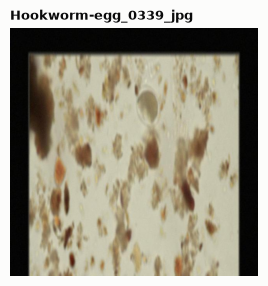

In [5]:
kept = set(images.image.map(lambda p: p.name))
dropped = []
for img in sorted(SRC.glob("*/images/*")):
    if img.name.startswith(("Ascaris", "Hookworm", "Trichuris")) and img.name not in kept:
        lbl = img.parent.parent / "labels" / f"{img.stem}.txt"
        labels = [SRC_NAMES[c] for c, *_ in read_yolo(lbl)] if lbl.exists() else None
        dropped.append({"path": img, "imagen": str(img.relative_to(SRC)),
                        "cajas en la etiqueta": labels if labels is not None else "sin archivo"})
display(pd.DataFrame(dropped).drop(columns="path") if dropped else "ninguna")

if dropped:
    fig, axes = plt.subplots(1, len(dropped), figsize=(3.2 * len(dropped), 3.4), squeeze=False)
    for ax, d in zip(axes[0], dropped):
        ax.imshow(Image.open(d["path"]))
        ax.set_title(d["path"].stem.split(".rf.")[0], fontsize=9)
        ax.axis("off")
    plt.show()

## 2. Integridad de etiquetas y de la partición

Se revisa que las etiquetas tengan el formato esperado y que las cajas caigan dentro de la
imagen, que ninguna foto original quede repartida entre particiones y que no haya fotos
repetidas o casi repetidas, sobre todo entre particiones: si la misma foto está en `train` y
en `test`, las métricas salen infladas.

In [6]:
issues = Counter()
for split in SPLITS:
    for lbl in (RAW / split / "labels").glob("*.txt"):
        for line in lbl.read_text().splitlines():
            parts = line.split()
            if not parts:
                continue
            if len(parts) != 5:
                issues["polygon_or_malformed"] += 1
                continue
            c, cx, cy, w, h = int(parts[0]), *map(float, parts[1:])
            issues["bad_class"] += c not in (0, 1, 2)
            issues["bad_size"] += not (0 < w <= 1 and 0 < h <= 1)
            eps = 1e-6
            issues["outside_image"] += (cx - w / 2 < -eps or cx + w / 2 > 1 + eps
                                        or cy - h / 2 < -eps or cy + h / 2 > 1 + eps)
issues = {k: v for k, v in issues.items() if v}
print("Problemas en etiquetas:", issues or "ninguno")
print("Fotos originales repartidas en más de una partición:",
      int((images.groupby("group").split.nunique() > 1).sum()))
print("Fotos originales con más de una copia:", int((images.group.value_counts() > 1).sum()))

Problemas en etiquetas: ninguno
Fotos originales repartidas en más de una partición: 0
Fotos originales con más de una copia: 0


**Duplicados.** Dos criterios:

- *Idénticos*: mismo contenido de píxeles (hash MD5 de la imagen decodificada).
- *Casi idénticos*: *difference hash* de 256 bits (la foto reducida a 17 × 16 en gris; cada bit
  dice si un píxel es más claro que su vecino de la derecha). La distancia de Hamming entre dos
  hashes es el número de bits distintos: 0 = misma estructura; fotos no relacionadas suelen
  diferir en más de 60. Las parejas más cercanas se muestran para revisarlas a ojo, porque el
  borde negro del ocular puede acercar fotos distintas.

Fotos con píxeles idénticos a otra foto: 0


,parejas,entre particiones
distancia ≤,,
0,0,0
5,0,0
10,0,0
20,2,1
30,72,36


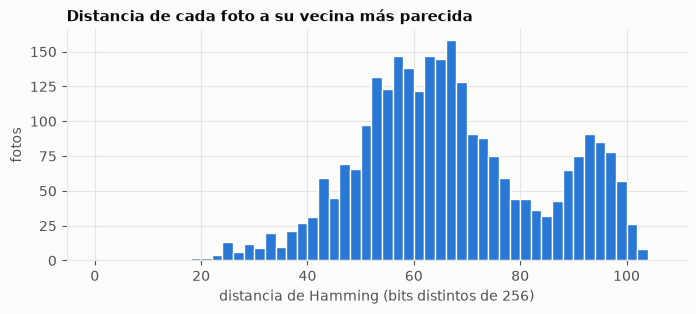

In [7]:
def pixel_md5(path):
    return hashlib.md5(np.asarray(Image.open(path).convert("RGB")).tobytes()).hexdigest()


def dhash_bits(path, size=16):
    """Difference hash: size*size bits comparing horizontally adjacent pixels."""
    g = np.asarray(Image.open(path).convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()


images["md5"] = images.image.map(pixel_md5)
n_identical = int(images.md5.duplicated(keep=False).sum())
print("Fotos con píxeles idénticos a otra foto:", n_identical)

bits = np.stack(images.image.map(dhash_bits)).astype(np.float32)
n_bits = bits.shape[1]
dist = n_bits - (bits @ bits.T + (1 - bits) @ (1 - bits).T)  # Hamming distance, all pairs
np.fill_diagonal(dist, n_bits)
images["nn_dist"] = dist.min(axis=1)
images["nn_idx"] = dist.argmin(axis=1)

ii, jj = np.triu_indices(len(images), k=1)
pairs = pd.DataFrame({"i": ii, "j": jj, "dist": dist[ii, jj]})
pairs["cross_split"] = images.split.values[pairs.i] != images.split.values[pairs.j]
summary = pd.DataFrame({t: {"parejas": int((pairs.dist <= t).sum()),
                            "entre particiones": int(((pairs.dist <= t) & pairs.cross_split).sum())}
                        for t in (0, 5, 10, 20, 30)}).T.rename_axis("distancia ≤")
display(summary)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(images.nn_dist, bins=np.arange(0, images.nn_dist.max() + 3, 2), color=COLORS["ascaris"],
        edgecolor=SURFACE, linewidth=1)
ax.set(title="Distancia de cada foto a su vecina más parecida",
       xlabel="distancia de Hamming (bits distintos de 256)", ylabel="fotos")
plt.show()

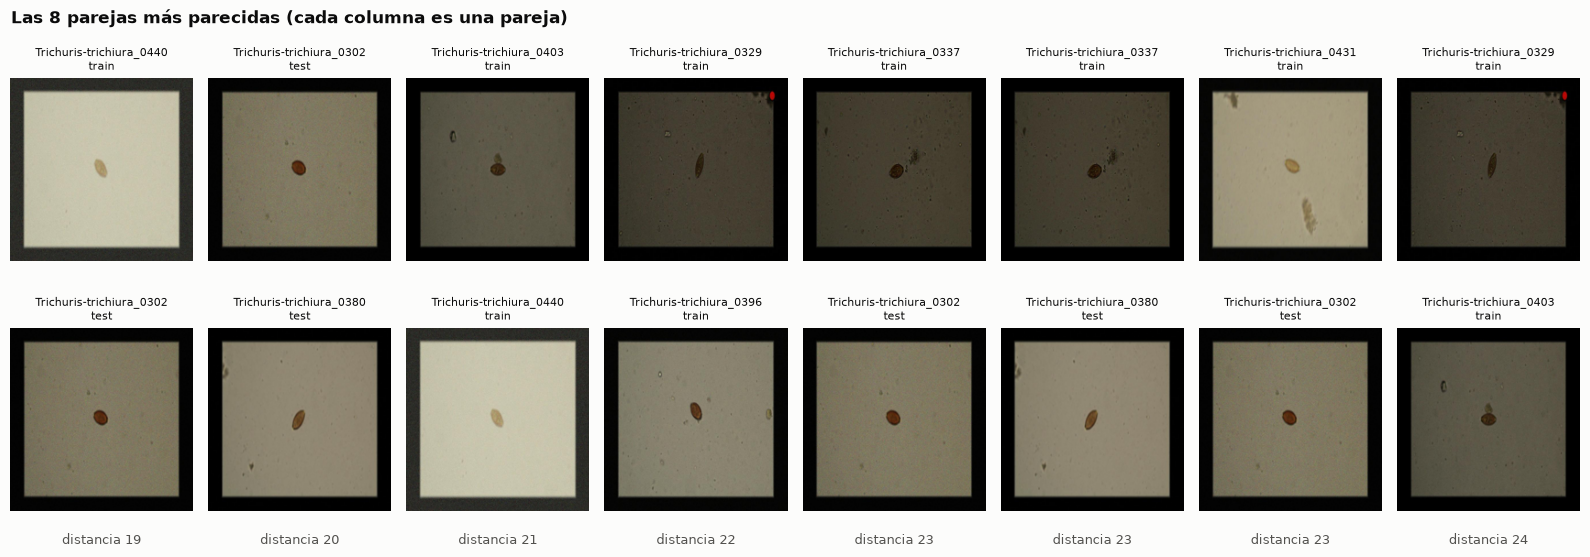

In [8]:
closest = pairs.nsmallest(8, "dist").reset_index(drop=True)
fig, axes = plt.subplots(2, 8, figsize=(16, 5.6))
for k, p in closest.iterrows():
    for row, idx in enumerate((p.i, p.j)):
        r = images.iloc[int(idx)]
        ax = axes[row, k]
        ax.imshow(Image.open(r.image).resize((200, 200)))
        ax.set_title(f"{r.group.split('_jpg')[0]}\n{r.split}", fontsize=8, loc="center", fontweight="normal")
        ax.axis("off")
    axes[1, k].text(0.5, -0.12, f"distancia {p.dist:.0f}", transform=axes[1, k].transAxes,
                    ha="center", va="top", fontsize=9, color=INK2)
fig.suptitle("Las 8 parejas más parecidas (cada columna es una pareja)", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout(h_pad=2.5)
plt.show()

## 3. Los huevos: tamaño, forma y posición

El tamaño se mide como el lado mayor de la caja, en píxeles de la foto de 640 × 640. Depende del
aumento del microscopio y del recorte de la foto, así que no es una medida física del huevo; sí
importa para el clasificador, porque cada recorte se lleva a 224 × 224 y un huevo pequeño se
agranda mucho (y pierde nitidez).

,count,min,10%,50%,90%,max,agrandamiento a 224 (mediana)
ascaris,910.0,46.0,61.5,96.5,189.0,313.5,1.8
hookworm,928.0,46.0,56.5,88.5,173.5,292.5,1.9
trichuris,911.0,36.0,45.0,71.0,150.0,264.0,2.4


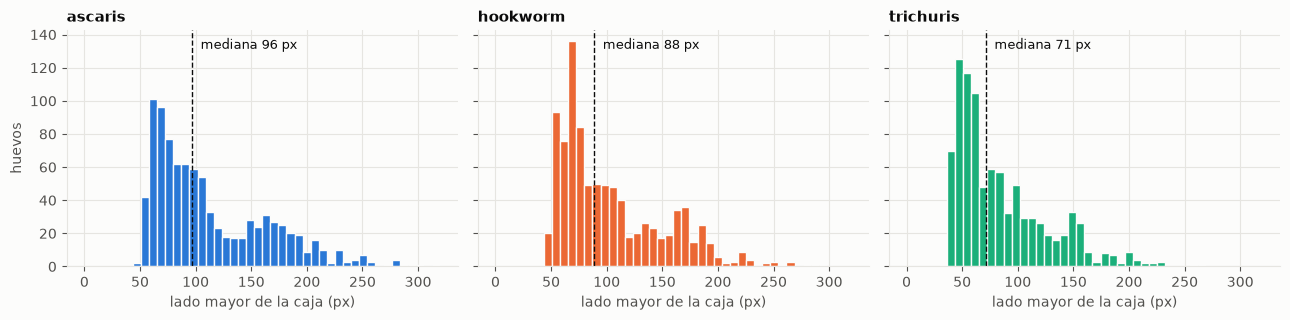

In [9]:
size_table = boxes.groupby("label").side_px.describe(percentiles=[.1, .5, .9])
size_table["agrandamiento a 224 (mediana)"] = 224 / (boxes.groupby("label").side_px.median() * 1.3)
display(size_table[["count", "min", "10%", "50%", "90%", "max", "agrandamiento a 224 (mediana)"]]
        .rename_axis(index=None).round(1))

bins = np.linspace(0, boxes.side_px.max() * 1.02, 45)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharex=True, sharey=True)
for ax, cls in zip(axes, CLASSES):
    s = boxes.loc[boxes.label == cls, "side_px"]
    ax.hist(s, bins=bins, color=COLORS[cls], edgecolor=SURFACE, linewidth=1)
    med = s.median()
    ax.axvline(med, color=INK, lw=1, ls="--")
    ax.text(med + 8, 0.92, f"mediana {med:.0f} px", transform=ax.get_xaxis_transform(),
            fontsize=9, color=INK)
    ax.set(title=cls, xlabel="lado mayor de la caja (px)")
axes[0].set_ylabel("huevos")
plt.tight_layout()
plt.show()

El agrandamiento supone el margen de 15 % por lado que usa `crop_eggs.py` (caja × 1,3).

**Forma y deformación.** Los huevos aparecen en cualquier orientación, así que el promedio de
log(ancho / alto) debería ser ≈ 0. Un promedio distinto de 0 indica que las fotos se deformaron al
redimensionarlas (Roboflow las estiró a 640 × 640).

,mean,std,count,ancho relativo (exp media)
ascaris,-0.078,0.490,910,0.925
hookworm,-0.082,0.548,928,0.921
trichuris,-0.061,0.688,911,0.941
todas,-0.074,0.581,2749,0.929


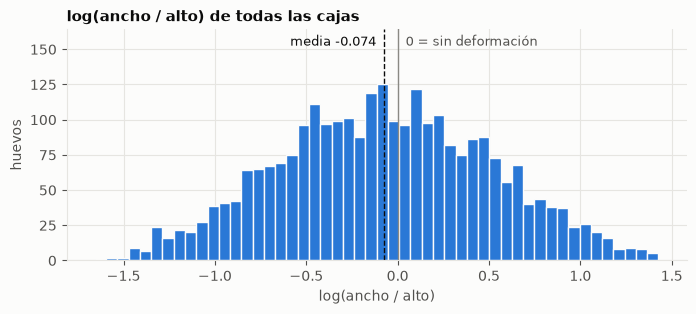

In [10]:
aspect = boxes.groupby("label").log_aspect.agg(["mean", "std", "count"])
aspect.loc["todas"] = [boxes.log_aspect.mean(), boxes.log_aspect.std(), len(boxes)]
aspect["ancho relativo (exp media)"] = np.exp(aspect["mean"])
display(aspect.rename_axis(index=None).round(3))

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(boxes.log_aspect, bins=50, color=COLORS["ascaris"], edgecolor=SURFACE, linewidth=1)
ax.axvline(0, color=MUTED, lw=1)
ax.axvline(boxes.log_aspect.mean(), color=INK, lw=1, ls="--")
ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
ax.text(boxes.log_aspect.mean(), 0.93, f"media {boxes.log_aspect.mean():+.3f}  ",
        transform=ax.get_xaxis_transform(), ha="right", fontsize=9)
ax.text(0, 0.93, "  0 = sin deformación", transform=ax.get_xaxis_transform(), fontsize=9, color=INK2)
ax.set(title="log(ancho / alto) de todas las cajas", xlabel="log(ancho / alto)", ylabel="huevos")
plt.show()

**Posición.** Dónde cae el centro de cada huevo dentro de la foto, y cuántos tocan el borde
(huevos cortados).

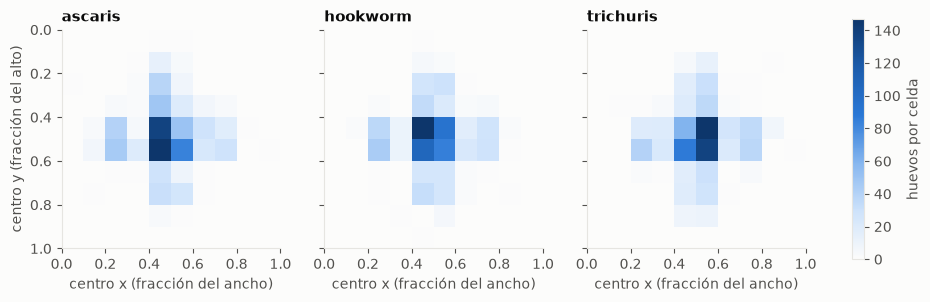

Huevos que tocan el borde de la foto: {'ascaris': '1.4%', 'hookworm': '0.8%', 'trichuris': '0.4%'}


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), sharey=True)
for ax, cls in zip(axes, CLASSES):
    b = boxes[boxes.label == cls]
    counts, _, _, mesh = ax.hist2d(b.cx, b.cy, bins=10, range=[[0, 1], [0, 1]], cmap=BLUES)
    ax.set(title=cls, xlabel="centro x (fracción del ancho)", aspect="equal")
    ax.invert_yaxis()
    ax.grid(False)
axes[0].set_ylabel("centro y (fracción del alto)")
fig.colorbar(mesh, ax=axes, shrink=0.8, label="huevos por celda")
plt.show()

edge = 0.01
touches = ((boxes.cx - boxes.w / 2 < edge) | (boxes.cx + boxes.w / 2 > 1 - edge)
           | (boxes.cy - boxes.h / 2 < edge) | (boxes.cy + boxes.h / 2 > 1 - edge))
print("Huevos que tocan el borde de la foto:",
      {cls: f"{touches[boxes.label == cls].mean():.1%}" for cls in CLASSES})

## 4. Las fotos: borde del ocular, brillo, color y nitidez

Muchas fotos se tomaron por el ocular y muestran el campo circular rodeado de negro (como las
fotos con celular que se tomarán en el Chocó). Para cada foto se mide, **sobre el fondo** (sin el
borde negro y sin el huevo, que se tapa con su caja más un margen de 15 %):

| Medida | Qué es |
|---|---|
| `black_frac` | Fracción de la foto que es borde negro (gris < 40) |
| `brightness` | Brillo medio del fondo (0–255) |
| `contrast` | Desviación estándar del gris del fondo |
| `warmth` | Rojo medio − azul medio del fondo: > 0 amarillento, < 0 azulado |
| `sharpness` | Varianza del laplaciano en el fondo: más alta = más nítida |
| `red_mark` | Área (px) de la mancha roja saturada más grande de la foto (puntero del ocular, §4.1) |

In [12]:
def photo_stats(path, egg_boxes):
    rgb = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    gray = rgb.mean(axis=2)
    H, W = gray.shape
    lit = gray >= BLACK
    egg = np.zeros_like(lit)
    for b in egg_boxes.itertuples():
        mw, mh = b.w * 0.15, b.h * 0.15
        x1, x2 = int(max(0, (b.cx - b.w / 2 - mw) * W)), int(min(W, (b.cx + b.w / 2 + mw) * W))
        y1, y2 = int(max(0, (b.cy - b.h / 2 - mh) * H)), int(min(H, (b.cy + b.h / 2 + mh) * H))
        egg[y1:y2, x1:x2] = True
    bg = lit & ~egg
    inner = ndimage.binary_erosion(bg, iterations=3)  # keep away from vignette and egg edges
    lap = ndimage.laplace(gray)
    red = (rgb[..., 0] > 150) & (rgb[..., 0] - rgb[..., 1] > 90) & (rgb[..., 0] - rgb[..., 2] > 90)
    blobs, n_blobs = ndimage.label(red)
    return {"black_frac": 1 - lit.mean(),
            "brightness": gray[bg].mean(),
            "contrast": gray[bg].std(),
            "warmth": rgb[..., 0][bg].mean() - rgb[..., 2][bg].mean(),
            "sharpness": lap[inner].var(),
            "red_mark": int(np.bincount(blobs.ravel())[1:].max()) if n_blobs else 0}


by_image = dict(tuple(boxes.groupby("image")))
stats = pd.DataFrame([photo_stats(p, by_image[p]) for p in images.image])
images = pd.concat([images.drop(columns=stats.columns, errors="ignore"), stats], axis=1)
display(images.groupby("label")[[c for c in stats.columns if c != "red_mark"]].median().rename_axis(index="mediana").round(2))

vignette = pd.DataFrame({f"> {t:.0%} de negro": images.groupby("label").black_frac.apply(lambda s: (s > t).mean())
                         for t in (0.05, 0.20, 0.40)})
display(vignette.rename_axis(index="fotos con borde").style.format("{:.1%}"))

,black_frac,brightness,contrast,warmth,sharpness
mediana,,,,,
ascaris,0.28,161.24,25.71,24.34,87.73
hookworm,0.31,153.01,35.52,29.81,126.82
trichuris,0.28,160.55,23.04,18.31,76.17


,> 5% de negro,> 20% de negro,> 40% de negro
fotos con borde,,,
ascaris,73.8%,71.2%,22.2%
hookworm,75.1%,70.9%,27.5%
trichuris,74.3%,69.6%,21.8%


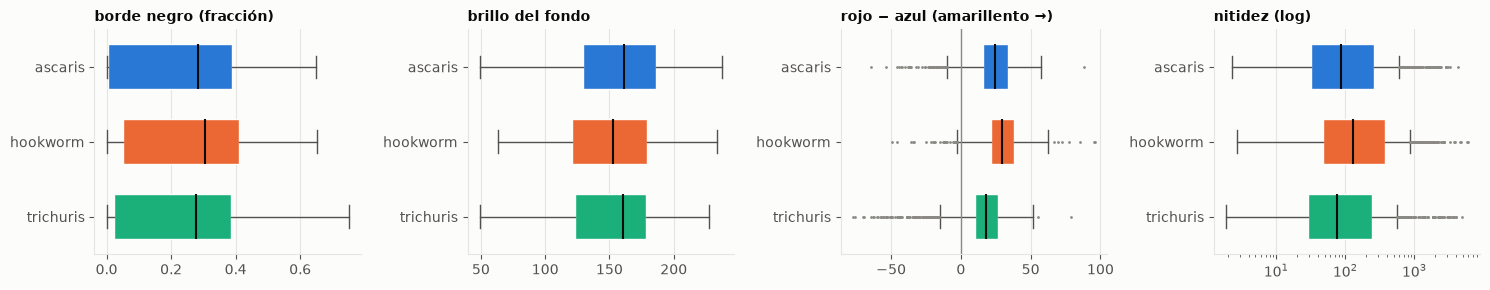

In [13]:
METRICS = [("black_frac", "borde negro (fracción)", False), ("brightness", "brillo del fondo", False),
           ("warmth", "rojo − azul (amarillento →)", False), ("sharpness", "nitidez (log)", True)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (col, title, log) in zip(axes, METRICS):
    data = [images.loc[images.label == cls, col] for cls in CLASSES]
    bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.6,
                    medianprops={"color": INK, "linewidth": 1.5},
                    flierprops={"marker": "o", "markersize": 2, "markerfacecolor": MUTED,
                                "markeredgecolor": "none"},
                    whiskerprops={"color": INK2}, capprops={"color": INK2})
    for patch, cls in zip(bp["boxes"], CLASSES):
        patch.set(facecolor=COLORS[cls], edgecolor=SURFACE)
    ax.set_yticks([1, 2, 3], CLASSES)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=10)
    if log:
        ax.set_xscale("log")
    if col == "warmth":
        ax.axvline(0, color=MUTED, lw=1)
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [14]:
def show_grid(rows, titles, row_labels=None, size=2.0, box=True):
    """rows: list of lists of images-table rows."""
    n_rows, n_cols = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows + 0.3), squeeze=False)
    for i, row in enumerate(rows):
        for j in range(n_cols):
            ax = axes[i, j]
            ax.axis("off")
            if j >= len(row):
                continue
            r = row[j]
            ax.imshow(Image.open(r.image))
            if box:
                for b in by_image[r.image].itertuples():
                    ax.add_patch(Rectangle(((b.cx - b.w / 2) * b.W, (b.cy - b.h / 2) * b.H),
                                           b.w * b.W, b.h * b.H, fill=False, lw=1.5,
                                           edgecolor=COLORS[b.label]))
            ax.set_title(titles[i][j], fontsize=8, loc="center", fontweight="normal")
        if row_labels:
            axes[i, 0].text(-0.06, 0.5, row_labels[i], transform=axes[i, 0].transAxes, rotation=90,
                            ha="right", va="center", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()


train = images[images.split == "train"]

### 4.1 El puntero del ocular

Varias fotos muestran una **flecha roja**: el puntero del ocular, que el microscopista coloca
señalando el huevo (a veces se ve también un punto rojo en una esquina). Se detecta de forma
aproximada como una mancha roja saturada de al menos 100 px. La regla también atrapa algunos
restos rojos del fondo (sobre todo en fotos amarillentas de uncinarias), así que los conteos son
una estimación; la grilla muestra las fotos de `train` con la mancha más grande.

,sin mancha,mancha roja ≥ 100 px,total
ascaris,807,95,902
hookworm,896,22,918
trichuris,896,15,911
total,2599,132,2731


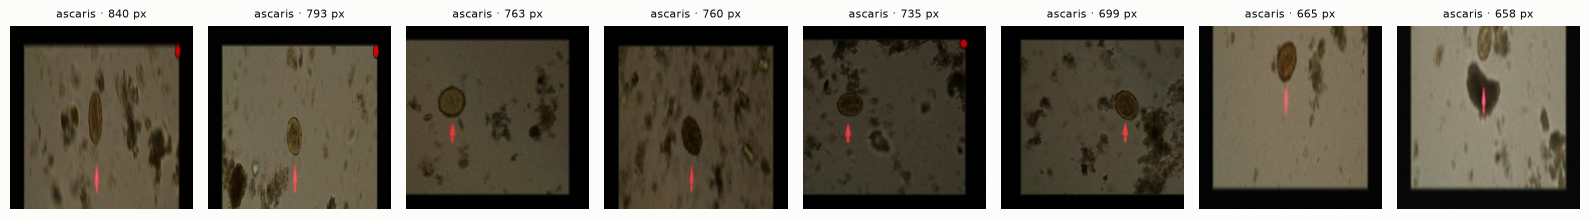

In [15]:
POINTER_PX = 100
has_red = images.red_mark >= POINTER_PX
display(pd.crosstab(images.label, has_red, margins=True, margins_name="total")
        .rename(columns={True: f"mancha roja ≥ {POINTER_PX} px", False: "sin mancha"})
        .rename_axis(index=None, columns=None))
top_red = train.nlargest(8, "red_mark")
show_grid([list(top_red.itertuples())], [[f"{r.label} · {r.red_mark} px" for r in top_red.itertuples()]],
          box=False)

### 4.2 Ejemplos

**Por clase** (solo `train`, elegidos al azar con la seed del proyecto; la caja es la anotación
original).

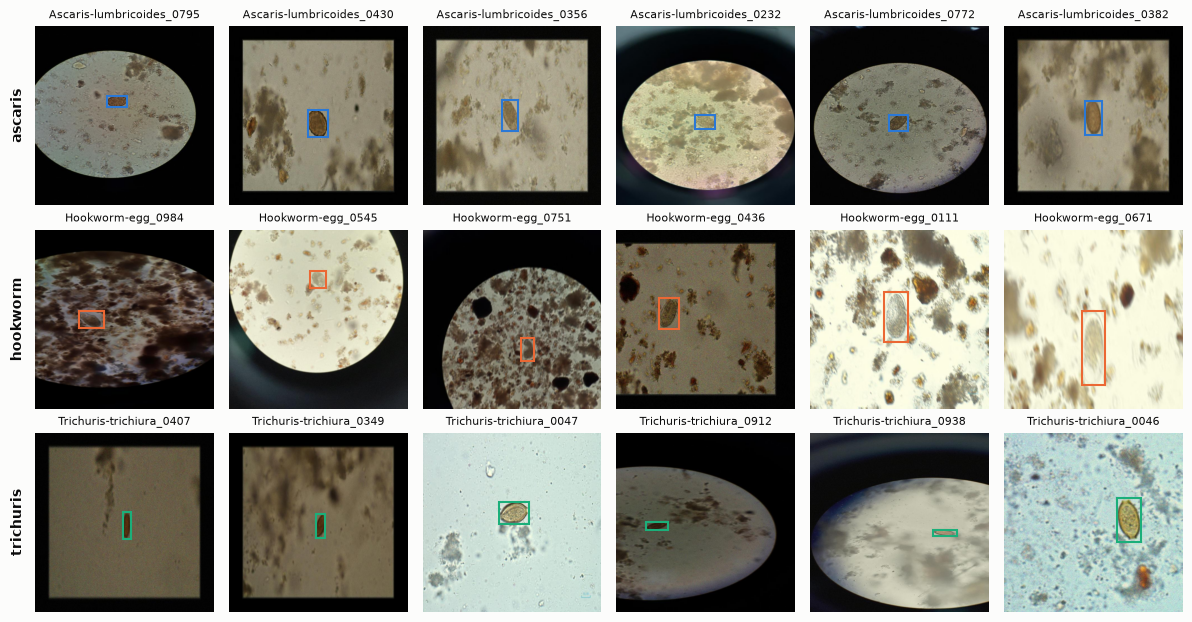

In [16]:

sample = [train[train.label == cls].sample(6, random_state=SEED).itertuples() for cls in CLASSES]
sample = [list(s) for s in sample]
show_grid(sample, [[r.group.split("_jpg")[0] for r in row] for row in sample], row_labels=CLASSES)

**Casos extremos** (solo `train`): las fotos más difíciles según cada medida. Sirven para
decidir aumentos de datos y para anticipar errores.

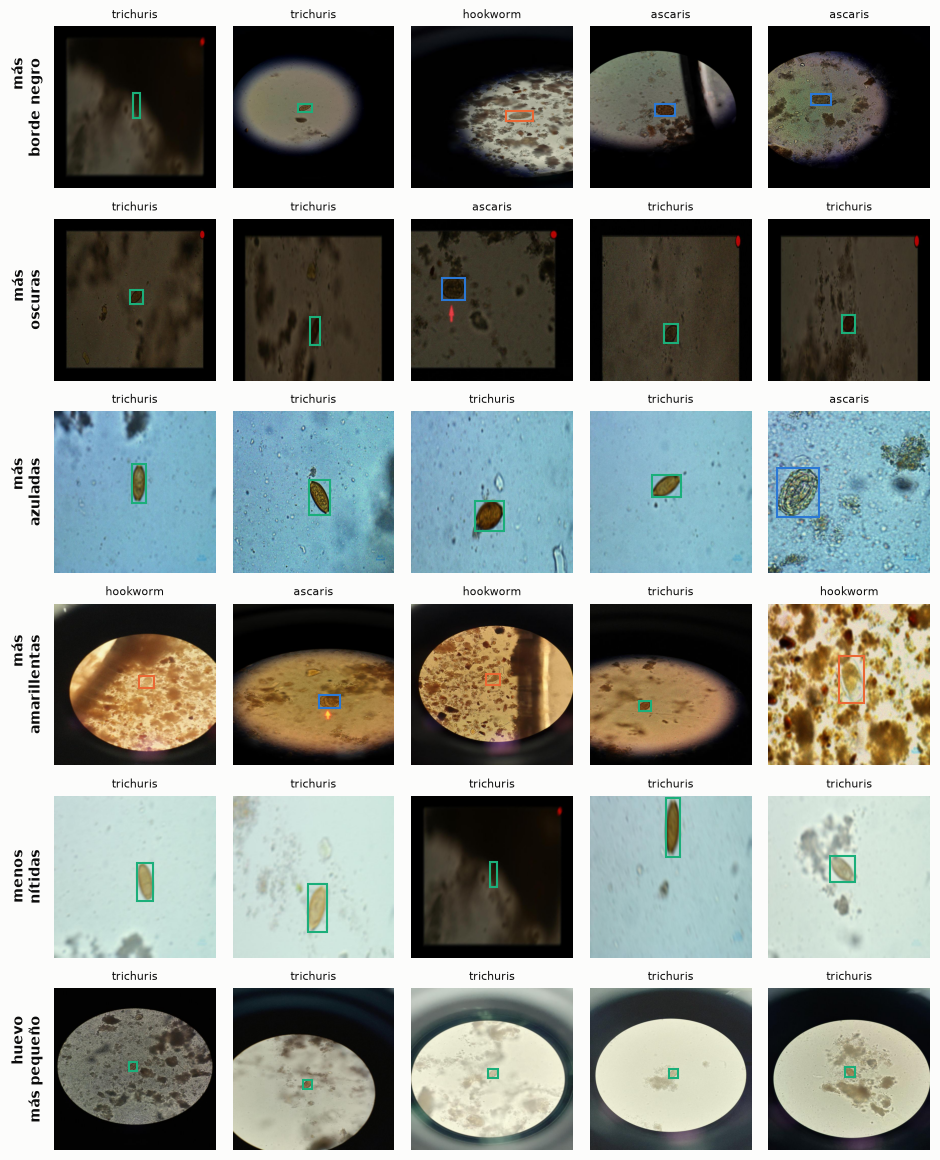

In [17]:
extremes = {
    "más borde negro": train.nlargest(5, "black_frac"),
    "más oscuras": train.nsmallest(5, "brightness"),
    "más azuladas": train.nsmallest(5, "warmth"),
    "más amarillentas": train.nlargest(5, "warmth"),
    "menos nítidas": train.nsmallest(5, "sharpness"),
    "huevo más pequeño": train.merge(boxes.groupby("image").side_px.min().rename("min_side"),
                                     left_on="image", right_index=True).nsmallest(5, "min_side"),
}
rows = [list(df.itertuples()) for df in extremes.values()]
titles = [[f"{r.label}" for r in row] for row in rows]
show_grid(rows, titles, row_labels=[k.replace(" ", "\n", 1) for k in extremes], size=1.9)

## 6. Conclusiones

**Lo que está bien**

- **Inventario balanceado y partición correcta.** 2731 fotos y 2749 huevos, unos 900 por clase.
  La partición queda exactamente en 70/15/15 por foto, con las mismas proporciones de clase en
  las tres particiones. 2713 fotos tienen un huevo y 18 tienen dos. Todas miden 640 × 640.
- **Etiquetas sanas.** No hay líneas mal formadas, clases fuera de rango ni cajas fuera de la
  imagen. Ninguna foto original está repartida entre particiones.
- **No hay duplicados.** Ninguna foto es idéntica a otra. La pareja más parecida difiere en 19 de
  256 bits del hash, y al revisarlas a ojo las parejas más cercanas son fotos distintas (otro
  huevo, otra posición).
- **Los huevos casi siempre están centrados.** Solo entre 0,4 % y 1,4 % tocan el borde de la foto.

**Lo que hay que tener en cuenta**

1. **Una foto sin anotación.** `Hookworm-egg_0339` muestra un huevo, pero su archivo de
   etiquetas está vacío, así que quedó fuera. Se documenta y no se corrige a mano; si se quiere
   recuperar, la decisión es del equipo.
2. **Deformación por estiramiento, confirmada.** El promedio de log(ancho/alto) es −0,074 y
   es casi igual en las tres clases. Las fotos quedaron comprimidas cerca de 7 % en horizontal.
   Afecta por igual a todas las especies y se reporta como limitación.
3. **Huevos pequeños.** Las medianas del lado mayor son 96 px (ascaris), 88 px (hookworm) y
   71 px (trichuris); el mínimo es 36 px. Al llevar el recorte a 224 px, la mediana se agranda
   entre 1,8 y 2,4 veces. Los histogramas tienen dos picos, lo que sugiere fotos tomadas con
   dos aumentos distintos (es una hipótesis, sin verificar). Ambos puntos apoyan pedir una
   versión de Roboflow sin redimensionar.
4. **Sesiones de captura compartidas entre particiones.** Las parejas más parecidas son fotos
   distintas de una misma sesión (mismo marco cuadrado, fondo e iluminación), y algunas quedan
   una en `train` y otra en `test`. No es fuga de la misma foto, pero el `test` interno se
   parece más al entrenamiento que las fotos de otra fuente.
5. **El puntero del ocular delata a *Ascaris*.** Hay una mancha roja de al menos 100 px en
   95 de 902 fotos de ascaris (10,5 %), frente a 22 de 918 de hookworm y 15 de 911 de trichuris.
   Los conteos son aproximados, porque en hookworm parte de lo detectado es suciedad roja. Además,
   la flecha apunta justo al huevo.
6. **Hay atajos en el fondo de la foto.** Con solo el fondo (huevo tapado), un random forest
   acierta la especie con exactitud balanceada de **0,635 ± 0,013**, cuando el azar da 0,333.
   La regresión logística llega a 0,529. Reconoce el 74 % de las uncinarias y el 71 % de los
   trichuris sin mirar el huevo. Las medidas que más pesan son contraste, color (rojo − azul) y
   brillo: los fondos de hookworm tienen más contraste y nitidez, y los de trichuris son menos
   amarillentos. Es decir, cada especie se fotografió en buena parte en condiciones propias.

**Implicaciones para el modelado (propuestas para el equipo)**

- **Aumentos de datos.** Hacen falta aumentos fuertes de color, brillo, contraste y desenfoque,
  y un **puntero sintético en todas las clases**. Así esas pistas dejan de predecir la especie.
  Ambos ya estaban previstos en PLAN §5.8, y ahora tienen evidencia.
- **Clasificar recortes ayuda pero no basta.** El recorte reduce el fondo que ve el modelo, pero
  el margen de 15 % conserva algo. Conviene repetir esta prueba de atajos sobre el margen de los
  recortes y revisar con Grad-CAM que el modelo mire el huevo.
- **El `test` interno será optimista.** La medida que de verdad cuenta es la prueba externa
  (UPB y fotos de campo, PLAN §5.7), y la caída de F1 frente a ella es el criterio de éxito ya
  acordado.